[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TheBestProEver/100micron-sim/blob/main/notebooks/03_silica_vs_carbon.ipynb)

# 03 · Silica or carbon: which sticks more easily, and why?

**The question.** DOLL-E measures the speed below which ~100 µm grains stick, for carbon and for silicates. With the
simulator's material values, which pair sticks more easily, by how much, which material property causes the
difference, and how sure can we be?

**Which carbon?** The carbon DOLL-E will fly is not decided yet. This notebook uses **graphite**, the simulator's
carbon (values of Chokshi, Tielens & Hollenbach 1993, ApJ 407, 806, Table 3), and shows how the answer moves for other
carbons (glassy carbon from its data sheet, the table's amorphous carbon, graphite with other surface energies),
so the team can evaluate whichever carbon it chooses.

**After this notebook you can explain**
- which material numbers are measured and which are ASSUMED, and how uncertain each one is;
- the sticking-speed scaling law $v \propto \gamma^{5/6}E^{*-1/3}R^{*-5/6}\rho^{-1/2}$, derived from the energy balance, and
  why damping multiplies it by a factor that depends on $e_{dry}$ alone;
- why graphite sticks at about six times silica's speed, property by property;
- how the threshold changes over the grain sizes 45–106 µm;
- what this means for DOLL-E, and which measurements would settle it.

Symbols as in notebook 01: $\rho$ density [kg/m³], $E$ Young's modulus [Pa], $\nu$ Poisson ratio, $\gamma$ surface
energy per surface [J/m²], $e_{dry}$ dry restitution, $p_y$ yield pressure [Pa]; for a pair $E^*$, $R^*$, $m^*$ and
the work of adhesion $w$ [J/m²]. All grains here have radius $r$ = 50 µm (100 µm diameter) unless stated.

In [1]:
# Make the repository's packages (dolle_core, dolle_sim) importable, in Colab or from a local clone.
import sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules:   # in Colab: install the repository from GitHub (takes ~30 s)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/TheBestProEver/100micron-sim.git"], check=True)
else:                               # locally: the repository folder is this folder or the one above (notebooks/)
    sys.path.insert(0, str(next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "dolle_core").is_dir())))

In [2]:
import math
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
import dolle_core as dc                      # the readable core of the DOLL-E simulator
from dolle_core import nb_collisions as nb   # short plotting and bookkeeping helpers for these notebooks
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
import textwrap

## 1. The materials and where their numbers come from

The table below is `dolle_core/materials.py`, identical value by value to the full simulator's
`dolle_sim/materials.py` (checked by `tests/test_dolle_core.py`). Each material carries its own source note.

In [3]:
names = ["silica", "graphite", "amorphous_carbon", "carbon_silica_50_50"]
print(nb.property_table(names))
for n in names:
    print(f"\n{n}: " + textwrap.fill(dc.get_material(n).source, 112, subsequent_indent="    "))

material                rho kg/m3   E GPa    nu  gamma J/m2  e_dry  p_y GPa
silica                       2000    54.0  0.17      0.0250   0.85     3.00
graphite                     2200    10.0  0.32      0.0750   0.70     0.30
amorphous_carbon             1800    20.0  0.25      0.0500   0.70     1.50
carbon_silica_50_50          2100    30.0  0.20      0.0450   0.75     1.50

silica: Amorphous SiO2 spheres. gamma = 0.025 J/m^2, E = 54 GPa, nu = 0.17: the quartz values used by Chokshi, Tielens &
    Hollenbach (1993) ApJ 407, 806 and Dominik & Tielens (1997) ApJ 480, 647 (measured in air ~0.014-0.025
    J/m^2; Kimura et al. 2015, ApJ 812, 67, argue dry silica in vacuum has ~0.15-0.25 J/m^2; Kreuzig et al.
    2024, A&A 688, found no such rise for hydrophobic spheres). rho, e_dry and p_y ASSUMED.

graphite: The simulator's carbon. gamma = 0.075 J/m^2 (basal plane), E = 10 GPa, nu = 0.32, rho = 2200 kg/m^3: Chokshi,
    Tielens & Hollenbach (1993) Table 3. The cleavage energy of graphi

Some values the table does not contain, but which decide how sure we can be, come from the literature quoted in the
simulator's notes (PROVENANCE.md, "Material properties") and from a glassy-carbon data sheet. They are collected in
one place here so that every number used below is printed:

In [4]:
LIT = {   # value or (low, high), unit, source
    "silica gamma, microspheres in air":      ((0.014, 0.025), "J/m^2", "Heim, Blum, Preuss & Butt 1999, PRL 83, 3328 (0.014); Chokshi et al. 1993 (0.025)"),
    "silica gamma, dry hydrophilic, vacuum":  ((0.15, 0.25), "J/m^2", "Kimura et al. 2015, ApJ 812, 67"),
    "graphite gamma from cleavage energy":    (0.19, "J/m^2", "Wang et al. 2015, Nat. Commun. 6, 7853 (0.37 for 2 surfaces)"),
    "fused silica E, nu, density":            ((73e9, 0.16, 2200.0), "SI", "HPFS 7980 data sheet (simulator's fused_silica_glass)"),
    "glassy carbon E (grades G and K)":       (35.0, "GPa", "SIGRADUR glassy-carbon data sheet"),
    "glassy carbon density, grade G / K":     ((1420.0, 1540.0), "kg/m^3", "SIGRADUR glassy-carbon data sheet"),
    "glassy carbon Poisson ratio":            (0.17, "-", "literature value, not checked here: ASSUMED"),
}
for k, (val, unit, src) in LIT.items():
    print(f"{k:40s} {str(val):18s} {unit:7s} {src}")

silica gamma, microspheres in air        (0.014, 0.025)     J/m^2   Heim, Blum, Preuss & Butt 1999, PRL 83, 3328 (0.014); Chokshi et al. 1993 (0.025)
silica gamma, dry hydrophilic, vacuum    (0.15, 0.25)       J/m^2   Kimura et al. 2015, ApJ 812, 67
graphite gamma from cleavage energy      0.19               J/m^2   Wang et al. 2015, Nat. Commun. 6, 7853 (0.37 for 2 surfaces)
fused silica E, nu, density              (73000000000.0, 0.16, 2200.0) SI      HPFS 7980 data sheet (simulator's fused_silica_glass)
glassy carbon E (grades G and K)         35.0               GPa     SIGRADUR glassy-carbon data sheet
glassy carbon density, grade G / K       (1420.0, 1540.0)   kg/m^3  SIGRADUR glassy-carbon data sheet
glassy carbon Poisson ratio              0.17               -       literature value, not checked here: ASSUMED


> **Why this choice: these material values, and how uncertain they are.**
> - **Silica** ($\gamma$ = 0.025 J/m², $E$ = 54 GPa, $\nu$ = 0.17): the quartz values used in the dust-collision
>   literature (Chokshi et al. 1993; Dominik & Tielens 1997). $\gamma$ is the least certain: 0.014–0.025 J/m² measured
>   in air, but Kimura et al. (2015) argue that dry hydrophilic silica in vacuum reaches 0.15–0.25 J/m², while
>   Kreuzig et al. (2024, A&A 688) found no such rise for hydrophobic spheres: it depends on the powder's surface
>   chemistry. $\rho$ = 2000 kg/m³ is ASSUMED (fused silica is 2200 kg/m³); $e_{dry}$ = 0.85 and $p_y$ = 3 GPa are
>   ASSUMED. $E$ and $\nu$ are quartz values too: fused silica has $E$ = 73 GPa, $\nu$ = 0.16 (data sheet), which alone
>   lowers the threshold by 14 % (section 8). Which silica the team flies (amorphous Stöber spheres, fused silica,
>   soda-lime glass beads) decides $E$ and $\rho$.
> - **Graphite** ($\gamma$ = 0.075 J/m² for the basal plane, $E$ = 10 GPa, $\nu$ = 0.32, $\rho$ = 2200 kg/m³):
>   Chokshi et al. (1993), Table 3. The measured cleavage energy implies $\gamma$ ≈ 0.19 J/m² (Wang et al. 2015).
>   $e_{dry}$ = 0.7 and $p_y$ = 0.3 GPa are ASSUMED.
> - **Amorphous carbon** and the **50/50 carbon-silica mix** are placeholders: ALL values ASSUMED.
> - *Alternatives:* the team could measure $\gamma$ (pull-off or drop tests on the actual powders and walls,
>   e.g. Zafar et al. 2014, Powder Technol. 264, 236) and $e_{dry}$ (restitution of non-sticking impacts); until then
>   the sections below show how far each uncertain value moves the answer.

## 2. The contact numbers and sticking speed of each pair

For two equal grains of each material, and for a silica grain meeting a graphite grain (whose $w = 2\sqrt{\gamma_1\gamma_2}$
and $e_{dry} = \sqrt{e_1e_2}$ follow the simulator's ASSUMED mixing rules): reduced modulus $E^*$, work of adhesion $w$,
pull-off force $F_c = \frac32\pi wR^*$ (also as a multiple of the grain's weight on Earth), zero-load patch radius
$a_0$, break overlap $\delta_c$, hysteresis $|U_0|$, the undamped and damped sticking speeds, the yield speed and the
Tabor parameter with a surface-force range $z_0$ = 0.3 nm (ASSUMED; notebook 01 prints the range for 0.2–0.4 nm;
notebook 01 derives all of these). Sticking speeds use the simulator's default bisection tolerance
(2e-3), so they are the numbers the simulator itself uses.

In [5]:
r = 50e-6                                                  # grain radius [m]
pairs = {n: nb.pair_summary(n, r=r, tol=2e-3) for n in names}
pairs["silica-graphite"] = nb.pair_summary("silica", "graphite", r=r, tol=2e-3)
print(f"{'pair':20s} {'E* GPa':>7s} {'w J/m2':>7s} {'F_c uN':>7s} {'F_c/mg':>7s} {'a0 nm':>6s} {'d_c nm':>7s} "
      f"{'|U0| J':>9s} {'v0 mm/s':>8s} {'v_stick':>8s} {'v_y m/s':>7s} {'Tabor':>5s}")
for n, s in pairs.items():
    p = s["pair"]
    print(f"{n:20s} {s['E_star']/1e9:7.2f} {s['w']:7.4f} {s['F_c']*1e6:7.2f} {s['F_c']/(p.m1*dc.G0):7.0f} "
          f"{s['a0']*1e9:6.1f} {s['delta_c']*1e9:7.3f} {s['U0']:9.2e} {s['v_undamped']*1e3:8.3f} "
          f"{s['v_stick']*1e3:8.3f} {s['v_yield']:7.3f} {s['tabor']:5.2f}")
v_si, v_gr = pairs["silica"]["v_stick"], pairs["graphite"]["v_stick"]
print(f"\ngraphite / silica sticking speed: {v_gr / v_si:.3f};  silica-graphite pair: {pairs['silica-graphite']['v_stick']*1e3:.2f} mm/s")

pair                  E* GPa  w J/m2  F_c uN  F_c/mg  a0 nm  d_c nm    |U0| J  v0 mm/s  v_stick v_y m/s Tabor
silica                 27.80  0.0500    5.89     574  251.4  -0.696  3.83e-15    3.827    6.175  11.126  1.44
graphite                5.57  0.1500   17.67    1564  619.7  -4.226  6.99e-14   15.576   38.359   0.836  8.76
amorphous_carbon       10.67  0.1000   11.78    1275  435.9  -2.091  2.31e-14    9.891   24.328  14.086  4.33
carbon_silica_50_50    15.62  0.0900   10.60     983  370.6  -1.512  1.50e-14    7.385   15.825   6.077  3.13
silica-graphite         9.28  0.0866   10.20     993  435.2  -2.085  1.99e-14    8.518   17.188   0.308  4.32

graphite / silica sticking speed: 6.212;  silica-graphite pair: 17.19 mm/s


**Why this happens.** Graphite is five times softer than silica ($E^*$ 5.57 against 27.80 GPa) and three times
stickier ($w$ 0.15 against 0.05 J/m²). A softer, stickier contact makes a bigger patch and a deeper, wider neck
($\delta_c$ −4.23 against −0.70 nm), so its hysteresis $|U_0|$ is 18 times larger, while the grain is only 10 %
heavier. That gives 4.07 times silica's undamped sticking speed (15.58 against 3.83 mm/s), and graphite's lower
ASSUMED $e_{dry}$ raises it further: 38.359 against 6.175 mm/s, a factor 6.21. The mixed silica-graphite pair lies
in between (17.19 mm/s). The pull-off forces are hundreds to thousands of times the grains' weight on Earth: once stuck,
gravity cannot separate them.

## 3. Restitution against impact speed, for each pair

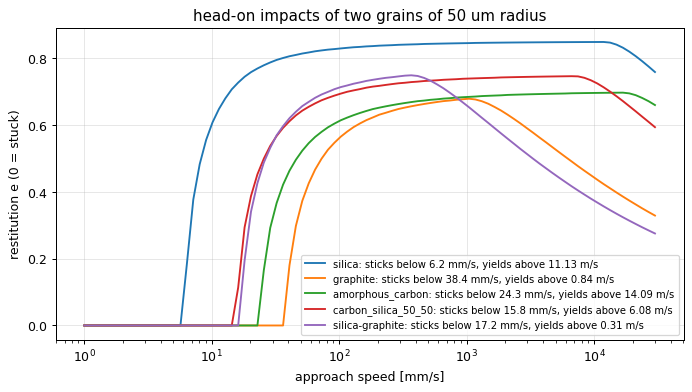

In [6]:
speeds = np.geomspace(1e-3, 30.0, 90)                     # approach speeds [m/s]
plt.figure(figsize=(9, 4.5))
for n, s in pairs.items():
    e, _ = nb.restitution_curve(s["pair"], speeds)
    plt.semilogx(speeds * 1e3, e, label=f"{n}: sticks below {s['v_stick']*1e3:.1f} mm/s, yields above {s['v_yield']:.2f} m/s")
plt.xlabel("approach speed [mm/s]"); plt.ylabel("restitution e (0 = stuck)")
plt.title("head-on impacts of two grains of 50 um radius"); plt.legend(fontsize=8); plt.show()

**Why this happens.** Each curve is zero below its sticking speed, rises steeply above it and levels off near its
pair's $e_{dry}$ (0.85 for silica, 0.70 for graphite and amorphous carbon, 0.75 for the mix). Graphite's curve then
falls from about 1 m/s, because its low ASSUMED yield pressure (0.3 GPa) makes it dent above 0.84 m/s; the mixed
silica-graphite pair dents even earlier (0.31 m/s: it has graphite's yield pressure but a stiffer contact, and
$v_y \propto p_y^{5/2}E^{*-2}\rho^{-1/2}$ from the formulas of notebook 01, section 11), and silica only above 11 m/s. For the sticking question only the left end of each curve matters.

## 4. The sticking speed by hand: an energy balance

**Without damping** two grains stick if the kinetic energy of their relative motion cannot pay the adhesion
hysteresis (notebook 01): $\frac12 m^*v^2 < |U_0|$, so $v_{stick,0} = \sqrt{2|U_0|/m^*}$, and $|U_0| = k_U\,w^{5/3}R^{*4/3}E^{*-2/3}$
with the pure number $k_U$ from the JKR curve. For two equal spheres of radius $r$:

1. $R^* = r/2$, so $r = 2R^*$;
2. $m^* = m/2 = \frac12\cdot\frac43\pi r^3\rho = \frac{16}{3}\pi R^{*3}\rho$;
3. $w = 2\gamma$;
4. $v_{stick,0}^2 = \dfrac{2k_U(2\gamma)^{5/3}R^{*4/3}E^{*-2/3}}{\frac{16}{3}\pi R^{*3}\rho}
   = \dfrac{3k_U}{8\pi}\,2^{5/3}\,\gamma^{5/3}E^{*-2/3}R^{*-5/3}\rho^{-1}$;
5. so $\boxed{\;v_{stick,0} = c\,\gamma^{5/6}E^{*-1/3}R^{*-5/6}\rho^{-1/2},\qquad c = \sqrt{\tfrac{3k_U}{8\pi}}\;2^{5/6}\;}$

Stickier ($\gamma$ up), softer ($E^*$ down), smaller ($R^*$ down) and lighter ($\rho$ down) grains stick at higher speeds.

In [7]:
print(f"k_U = {dc.hysteresis_constant():.4f};  c = sqrt(3 k_U/(8 pi)) 2^(5/6) = {dc.equal_spheres_prefactor():.4f}")
for n in ("silica", "graphite"):
    m, p = dc.get_material(n), pairs[n]["pair"]
    hand = dc.scaling_law_speed(m.gamma, p.E_star, p.R_star, m.rho)
    cdt = dc.chokshi_dominik_tielens_speed(m.gamma, p.E_star, p.R_star, m.rho)
    print(f"{n:8s}: hand formula {hand*1e3:.4f} mm/s, model sqrt(2|U0|/m*) {pairs[n]['v_undamped']*1e3:.4f} mm/s; "
          f"published 1.07 formula {cdt*1e3:.3f} mm/s ({cdt/hand:.3f} x)")
q = dc.make_pair("silica", 1e-6, "silica", 1e-6)               # two quartz spheres of 1 um radius: R* = 0.5 um
print("1.07 formula for micron-sized quartz (the review quotes about 5 cm/s): " + ", ".join(
      f"{dc.chokshi_dominik_tielens_speed(0.025, q.E_star, q.R_star, rho)*100:.1f} cm/s at rho = {rho}" for rho in (2000, 2650)))

k_U = 7.0922;  c = sqrt(3 k_U/(8 pi)) 2^(5/6) = 1.6394
silica  : hand formula 3.8266 mm/s, model sqrt(2|U0|/m*) 3.8266 mm/s; published 1.07 formula 2.497 mm/s (0.653 x)
graphite: hand formula 15.5758 mm/s, model sqrt(2|U0|/m*) 15.5758 mm/s; published 1.07 formula 10.166 mm/s (0.653 x)
1.07 formula for micron-sized quartz (the review quotes about 5 cm/s): 6.5 cm/s at rho = 2000, 5.7 cm/s at rho = 2650


**Why this happens.** The hand formula reproduces the model's undamped sticking speed exactly: it is the same
energy balance. Chokshi, Tielens & Hollenbach (1993) derived the same exponents, with $R$ the reduced radius and a
coefficient that the review of Beckwith, Henning & Nakagawa (2000, "Dust properties and assembly of large particles
in protoplanetary disks", *Protostars and Planets IV*, eq. 8 and its footnote) corrects from 3.86 to 1.07. That
formula gives 0.653 times this model's speed because its energy loss is different: Chokshi et al. assume the energy
is carried away mainly by elastic surface waves, while here it is the JKR hysteresis $|U_0|$ (plus damping). The
definitions agree: with $E = E^*$ and $R = R^*$ the 1.07 formula reproduces the review's "about 5 cm/s" for
micron-sized quartz (last line; 2650 kg/m³ is quartz's density, ASSUMED here). The comparison is listed for
transparency; the model's own number is the one that follows from its JKR curve.

## 5. Damping is one number: $v_{stick} = f(e_{dry})\,v_{stick,0}$

Measure lengths in units of $|\delta_c|$, forces in units of $F_c$ and times in units of
$\tau = \sqrt{m^*|\delta_c|/F_c}$. In these units the JKR curve is the SAME for every material ($F/F_c$ and
$\delta/|\delta_c|$ depend only on $a/a_0$; notebook 01, section 2.3), and the equation of motion
$m^*\ddot\delta = -F_{el} - c_d\sqrt{a}\,\dot\delta$ becomes

$$\ddot x = -\tilde F(x) - 2\sqrt{5/6}\;|\beta|\;\sqrt{\frac{2E^*a_0|\delta_c|}{F_c}}\;\sqrt{\tilde a}\;\dot x,
\qquad x = \delta/|\delta_c|,\ \tilde a = a/a_0 .$$

The group $E^*a_0|\delta_c|/F_c$ is a pure number: $a_0 \propto (wR^{*2}/E^*)^{1/3}$, $|\delta_c| \propto (w^2R^*/E^{*2})^{1/3}$ and
$F_c \propto wR^*$, so it is $\propto E^*\cdot wR^*E^{*-1}/(wR^*)$, a constant. So the only free number left is $\beta$,
i.e. $e_{dry}$: whether a pair sticks depends only on its incoming energy in units of $F_c|\delta_c|$ and on $e_{dry}$.
Since $|U_0| = 0.9355\,F_c|\delta_c|$ for every pair (notebook 01, section 2.4), the threshold in units of $v_{stick,0}$
depends on $e_{dry}$ alone. (The code's time step is the same in these units too, so even the discrete algorithm obeys this.)
The cell measures $f$ on four very different pairs, with yield switched off.

In [8]:
refs = {"silica pair": dc.make_pair("silica", r, "silica", r, plastic=False),
        "graphite pair": dc.make_pair("graphite", r, "graphite", r, plastic=False),
        "silica on borosilicate wall": dc.make_pair("silica", r, "glass_borosilicate", None, plastic=False),
        "graphite pair, r = 25 um": dc.make_pair("graphite", 25e-6, "graphite", 25e-6, plastic=False)}
for label, p in refs.items():
    f85, f70 = (dc.damping_factor(e, n_sub=300, tol=1e-5, pair=p) for e in (0.85, 0.70))
    print(f"{label:28s} f(0.85) = {f85:.5f}   f(0.70) = {f70:.5f}   ratio {f70/f85:.4f}")
e_grid = np.array([0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99])
f_grid = np.array([dc.damping_factor(e, n_sub=300, tol=1e-5, pair=refs["graphite pair"]) for e in e_grid])
print("f(e_dry) on the graphite pair:", ", ".join(f"f({e:g}) = {f:.3f}" for e, f in zip(e_grid, f_grid)))

silica pair                  f(0.85) = 1.61479   f(0.70) = 2.46108   ratio 1.5241
graphite pair                f(0.85) = 1.61479   f(0.70) = 2.46107   ratio 1.5241


silica on borosilicate wall  f(0.85) = 1.61479   f(0.70) = 2.46108   ratio 1.5241


graphite pair, r = 25 um     f(0.85) = 1.61479   f(0.70) = 2.46107   ratio 1.5241


f(e_dry) on the graphite pair: f(0.5) = 4.439, f(0.6) = 3.270, f(0.7) = 2.461, f(0.75) = 2.141, f(0.8) = 1.862, f(0.85) = 1.615, f(0.9) = 1.392, f(0.95) = 1.189, f(0.99) = 1.037


**Why this happens.** $f$ agrees to five or six digits across silica, graphite, a wall and a smaller grain: as the
argument says, even the discrete code sees the same problem in these units. So damping enters the sticking speed
as a single factor set by the ASSUMED $e_{dry}$: $f(0.85)$ = 1.615 and $f(0.70)$ = 2.461, a ratio of 1.52. Without
damping ($e_{dry} \to 1$) $f \to 1$ (1.037 at 0.99). $f$ depends weakly on the number of steps per contact (it is a
property of the discrete break detection too): $f(0.70)$ = 2.461 at the simulator's 300 steps, 2.459 at 2000
(`dc.damping_factor`'s default, `dolle_core/scaling.py`).

## 6. Which property causes the difference? Change one at a time

Start from silica and give it ONE of graphite's six values at a time; measure the sticking speed with the full
model (bisection tolerance 1e-4) and compare with the hand prediction: the scaling law of section 4 times $f(e_{dry})$
measured on the graphite pair (section 5). Last row: all six changed, i.e. graphite.

In [9]:
rows = nb.swap_properties("silica", "graphite", tol=1e-4)
print(f"{'graphite value of':24s} {'full model':>10s} {'hand':>8s}   yield speed of the changed pair")
for row in rows:
    print(f"{row['property']:24s} {row['measured']:10.4f} {row['predicted']:8.4f}   {row['v_yield']:.3f} m/s")
meas = {r_["property"]: r_["measured"] for r_ in rows}
print(f"\nproduct of the six single changes {math.prod(list(meas.values())[:-1]):.4f}; all six at once {meas['all']:.4f}")
print(f"stiffness (E and nu together) x{meas['E']*meas['nu']:.4f}; everything except e_dry x{meas['all']/meas['e_dry']:.4f}")
ln_total = math.log(rows[-1]["measured"])
print("share of ln(ratio):", ", ".join(f"{r_['property']} {math.log(r_['measured'])/ln_total:+.0%}" for r_ in rows[:-1]))

graphite value of        full model     hand   yield speed of the changed pair
gamma                        2.4981   2.4980   11.126 m/s
E                            1.7545   1.7544   324.426 m/s
nu                           0.9741   0.9741   9.505 m/s
rho                          0.9535   0.9535   10.608 m/s
e_dry                        1.5241   1.5241   11.126 m/s
yield_pressure               1.0000   1.0000   0.035 m/s
all                          6.2039   6.2037   0.836 m/s

product of the six single changes 6.2045; all six at once 6.2039
stiffness (E and nu together) x1.7091; everything except e_dry x4.0705
share of ln(ratio): gamma +50%, E +31%, nu -1%, rho -3%, e_dry +23%, yield_pressure +0%


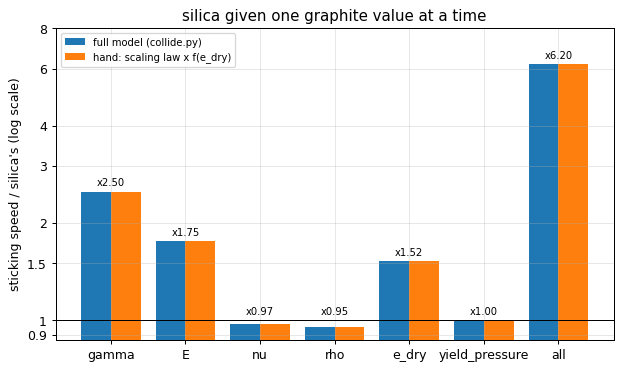

In [10]:
nb.plot_swap_bars(rows, "silica given one graphite value at a time"); plt.show()

**Why this happens.** The full model and the hand prediction agree to about 1e-4 for every property, and the six
single changes multiply to the total (6.2045 against 6.2039), because the sticking speed is a product of power laws
times $f(e_{dry})$. In order of importance:

- **surface energy** ×2.50 = $3^{5/6}$: graphite's $\gamma$ is three times silica's;
- **Young's modulus** ×1.75 = $(E^*$ ratio$)^{-1/3}$: the softer contact makes a bigger, more lossy neck;
- **e_dry** ×1.52: graphite's ASSUMED dry restitution is lower, so damping takes more;
- **density** ×0.95 and **Poisson ratio** ×0.97: small (the heavier grain brings more energy; a larger $\nu$
  slightly stiffens $E^* = E/(2(1-\nu^2))$);
- **yield pressure** ×1.00: no effect, because even with graphite's low $p_y$ a silica pair would only dent above
  0.035 m/s, above silica's sticking speed (0.006 m/s).

In shares of the logarithm, surface energy gives about half, the modulus 31 %, $e_{dry}$ 23 %. So 77 % of the
difference comes from the material constants (all published except silica's density) and 23 % from the ASSUMED
$e_{dry}$: with equal $e_{dry}$ the ratio would be 4.07 instead of 6.20.

## 7. Grain size: 45 to 106 µm

A sieve range names grain **diameters** (sieve openings); here $D$ = 45–106 µm, i.e. radii of 22.5–53 µm. The scaling
law predicts $v_{stick} \propto R^{*-5/6} \propto D^{-5/6}$ (the factor $f(e_{dry})$ does not depend on size).

silica  : 45 um 12.02 mm/s, 53 um 10.49 mm/s, 63 um 9.08 mm/s, 75 um 7.85 mm/s, 90 um 6.75 mm/s, 106 um 5.89 mm/s;  45/106 um ratio 2.042


graphite: 45 um 74.57 mm/s, 53 um 65.07 mm/s, 63 um 56.34 mm/s, 75 um 48.72 mm/s, 90 um 41.85 mm/s, 106 um 36.52 mm/s;  45/106 um ratio 2.042
(106/45)^(5/6) = 2.042


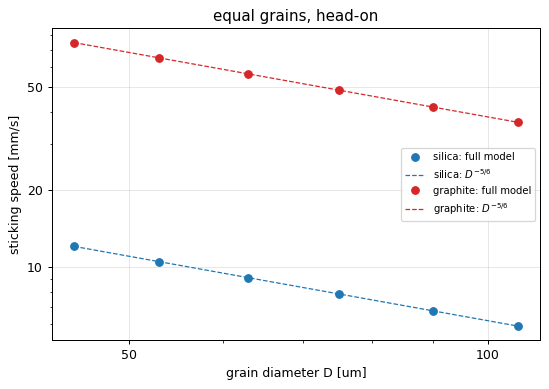

In [11]:
D = np.array([45, 53, 63, 75, 90, 106]) * 1e-6               # grain diameters [m]
plt.figure(figsize=(7, 4.5))
for n, col in (("silica", "C0"), ("graphite", "C3")):
    v = np.array([nb.threshold_of(n, d / 2) for d in D])
    plt.loglog(D * 1e6, v * 1e3, "o", color=col, label=f"{n}: full model")
    plt.loglog(D * 1e6, v[3] * (D / D[3]) ** (-5 / 6) * 1e3, "--", color=col, lw=1, label=f"{n}: $D^{{-5/6}}$")
    print(f"{n:8s}: " + ", ".join(f"{d*1e6:.0f} um {x*1e3:.2f} mm/s" for d, x in zip(D, v)) +
          f";  45/106 um ratio {v[0]/v[-1]:.3f}")
print(f"(106/45)^(5/6) = {(106/45)**(5/6):.3f}")
plt.xlabel("grain diameter D [um]"); plt.ylabel("sticking speed [mm/s]"); plt.title("equal grains, head-on")
nb.plain_log_axis(nb.plain_log_axis(plt.gca(), "x"), "y"); plt.legend(fontsize=8); plt.show()

**Why this happens.** The model's thresholds follow $D^{-5/6}$ exactly: small grains carry less kinetic energy
($\propto D^3$) for the same speed, while the hysteresis energy falls more slowly ($\propto D^{4/3}$). Across the
45–106 µm range the threshold changes by a factor 2.04 for both materials, smaller than the factor 6.2 between them,
so the material difference survives any size mix within the range. Silica pairs stick below 5.9 mm/s (106 µm) to
12.0 mm/s (45 µm), graphite pairs below 36.5 to 74.6 mm/s.

## 8. Other carbons, and how sure we are

Each row changes the table values as stated (sourced in section 1; ASSUMED where marked) and computes the sticking
speed of two 50 µm grains with the full model (bisection tolerance 1e-4, so the table values can differ from
section 2's in the third digit), plus the Tabor parameter ($z_0$ = 0.3 nm, ASSUMED; JKR is accurate above about 3–5,
notebook 01).

In [12]:
gr, si = dc.get_material("graphite"), dc.get_material("silica")
glassy = dict(E=35e9, nu=0.17)                             # data sheet E; nu ASSUMED; gamma, e_dry, p_y = graphite's (ASSUMED)
variants = {"silica (table)": si, "silica, gamma 0.014 (air, low end)": replace(si, gamma=0.014),
            "silica, gamma 0.15 (vacuum, Kimura)": replace(si, gamma=0.15), "silica, gamma 0.25 (vacuum, Kimura)": replace(si, gamma=0.25),
            "silica, rho 2200": replace(si, rho=2200.0), "silica, fused (E 73 GPa, nu 0.16, rho 2200)": replace(si, E=73e9, nu=0.16, rho=2200.0),
            "silica, e_dry 0.70 (ASSUMED)": replace(si, e_dry=0.70),
            "graphite (table)": gr, "graphite, gamma 0.19 (cleavage)": replace(gr, gamma=0.19),
            "graphite, e_dry 0.85 (ASSUMED)": replace(gr, e_dry=0.85),
            "glassy carbon G, rho 1420": replace(gr, rho=1420.0, **glassy), "glassy carbon K, rho 1540": replace(gr, rho=1540.0, **glassy),
            "amorphous carbon (table, ALL ASSUMED)": dc.get_material("amorphous_carbon")}
vt = {k: nb.threshold_of(m) for k, m in variants.items()}
for k, m in variants.items():
    p = dc.make_pair(m, r, m, r)
    print(f"{k:44s} {vt[k]*1e3:7.2f} mm/s  x{vt[k]/vt['silica (table)']:5.2f} silica   Tabor {dc.tabor_parameter(p.R_star, p.w, p.E_star):5.2f}")

silica (table)                                  6.18 mm/s  x 1.00 silica   Tabor  1.44
silica, gamma 0.014 (air, low end)              3.81 mm/s  x 0.62 silica   Tabor  0.98
silica, gamma 0.15 (vacuum, Kimura)            27.50 mm/s  x 4.45 silica   Tabor  4.76
silica, gamma 0.25 (vacuum, Kimura)            42.10 mm/s  x 6.81 silica   Tabor  6.69
silica, rho 2200                                5.89 mm/s  x 0.95 silica   Tabor  1.44
silica, fused (E 73 GPa, nu 0.16, rho 2200)     5.33 mm/s  x 0.86 silica   Tabor  1.18
silica, e_dry 0.70 (ASSUMED)                    9.42 mm/s  x 1.52 silica   Tabor  1.44
graphite (table)                               38.33 mm/s  x 6.20 silica   Tabor  8.76
graphite, gamma 0.19 (cleavage)                83.17 mm/s  x13.46 silica   Tabor 16.27
graphite, e_dry 0.85 (ASSUMED)                 25.15 mm/s  x 4.07 silica   Tabor  8.76
glassy carbon G, rho 1420                      32.26 mm/s  x 5.22 silica   Tabor  4.00
glassy carbon K, rho 1540                  

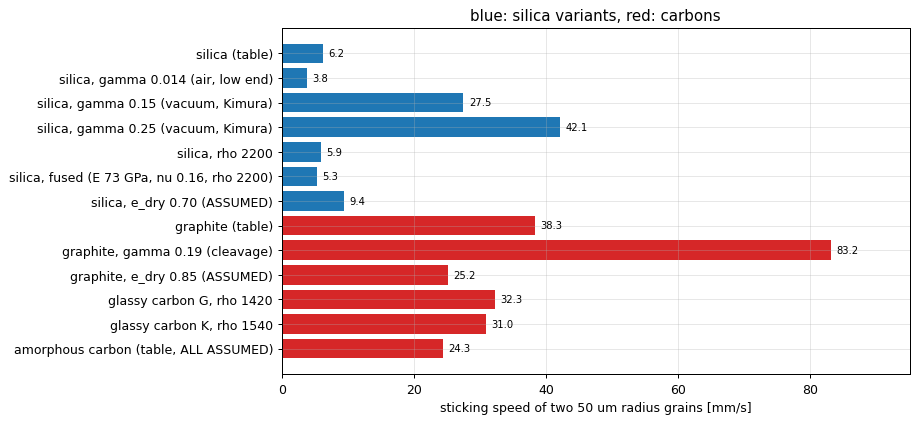

In [13]:
labels = list(vt)
colors = ["C0" if k.startswith("silica") else "C3" for k in labels]
plt.figure(figsize=(9, 5))
plt.barh(labels, [vt[k] * 1e3 for k in labels], color=colors)
for i, k in enumerate(labels):
    plt.text(vt[k] * 1e3 + 0.8, i, f"{vt[k]*1e3:.1f}", va="center", fontsize=8)
plt.gca().invert_yaxis(); plt.xlim(0, 95)
plt.xlabel("sticking speed of two 50 um radius grains [mm/s]")
plt.title("blue: silica variants, red: carbons"); plt.show()

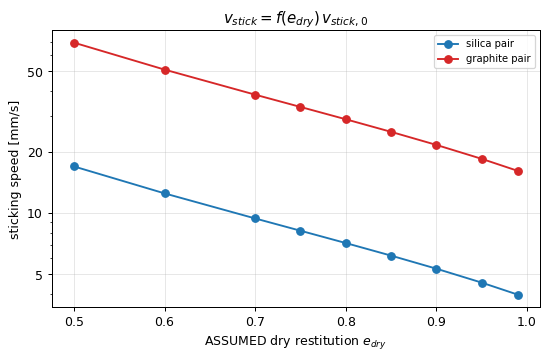

over e_dry = 0.5 to 0.99: silica 17.0 to 3.97 mm/s, graphite 69.1 to 16.15 mm/s


In [14]:
v0_si, v0_gr = pairs["silica"]["v_undamped"], pairs["graphite"]["v_undamped"]
plt.figure(figsize=(7, 4))
plt.plot(e_grid, f_grid * v0_si * 1e3, "o-", label="silica pair")
plt.plot(e_grid, f_grid * v0_gr * 1e3, "o-", color="C3", label="graphite pair")
plt.xlabel("ASSUMED dry restitution $e_{dry}$"); plt.ylabel("sticking speed [mm/s]")
plt.yscale("log"); nb.plain_log_axis(plt.gca(), "y")
plt.title("$v_{stick} = f(e_{dry})\\, v_{stick,0}$"); plt.legend(fontsize=8); plt.show()
print(f"over e_dry = {e_grid[0]} to {e_grid[-1]}: silica {f_grid[0]*v0_si*1e3:.1f} to {f_grid[-1]*v0_si*1e3:.2f} mm/s, "
      f"graphite {f_grid[0]*v0_gr*1e3:.1f} to {f_grid[-1]*v0_gr*1e3:.2f} mm/s")

**Why this happens.** Every carbon variant sticks at a higher speed than table silica: 24 to 83 mm/s against
6.18 mm/s. With fused silica's elastic constants and density, silica sticks below 5.33 mm/s, 14 % lower. Glassy carbon is stiffer than graphite (35 against 10 GPa) but lighter, so with graphite's (ASSUMED)
surface energy and $e_{dry}$ it lands below graphite, at 31–32 mm/s; its Tabor parameter (4.0) is at the lower edge of
the JKR range, so for a stiff glassy carbon JKR becomes less certain too. The ordering is robust to the silica density, to equal $e_{dry}$, and to graphite's higher cleavage-based
surface energy (which widens the gap to 13×). It is **not** robust to silica's surface energy: if the silica powder
behaves like dry hydrophilic silica in vacuum ($\gamma$ = 0.15–0.25 J/m², Kimura et al. 2015), silica pairs would stick
below 27.5–42 mm/s, as high as graphite. The assumed $e_{dry}$ alone moves each threshold by a factor of about 4.3
over 0.5–0.99 (silica 17.0 to 3.97 mm/s).

### A band for each kind of carbon

The scaling law times $f(e_{dry})$ is exact here (section 6 agrees with the full model to 1e-4), so it can give the
threshold band of each kind of carbon over the range of each property in one line. Each range is sourced or ASSUMED
as stated (glassy carbon's $\gamma$ and the whole amorphous-carbon row have no measurement behind them):

| carbon | $\gamma$ [J/m²] | $E$ [GPa] | $\nu$ | $\rho$ [kg/m³] | $e_{dry}$ |
|---|---|---|---|---|---|
| graphite | 0.075 (Chokshi et al. 1993) – 0.19 (Wang et al. 2015) | 5–15, ASSUMED around the table's 10 | 0.2–0.32, ASSUMED | 1700–2260, ASSUMED (synthetic bulk to crystal density; powders may be lighter) | 0.5–0.85, ASSUMED |
| glassy carbon | 0.075–0.19, ASSUMED as graphite | 35 (SIGRADUR data sheet) | 0.15–0.2, ASSUMED | 1420–1540 (data sheet) | 0.5–0.85, ASSUMED |
| amorphous carbon | 0.05–0.15, ASSUMED | 10–50, ASSUMED | 0.2–0.3, ASSUMED | 1500–2000, ASSUMED | 0.5–0.85, ASSUMED |

In [15]:
bands = {"graphite": dict(gamma=(0.075, 0.19), E=(5e9, 15e9), nu=(0.2, 0.32), rho=(1700, 2260), e_dry=(0.5, 0.85)),
         "glassy carbon": dict(gamma=(0.075, 0.19), E=35e9, nu=(0.15, 0.2), rho=(1420, 1540), e_dry=(0.5, 0.85)),
         "amorphous carbon": dict(gamma=(0.05, 0.15), E=(10e9, 50e9), nu=(0.2, 0.3), rho=(1500, 2000), e_dry=(0.5, 0.85))}
check = nb.scaling_band(dict(gamma=gr.gamma, E=gr.E, nu=gr.nu, rho=gr.rho, e_dry=gr.e_dry), e_grid, f_grid)[0]
print(f"check: table graphite by the band formula {check*1e3:.2f} mm/s, full model {vt['graphite (table)']*1e3:.2f} mm/s")
for name, rg in bands.items():
    lo, hi = nb.scaling_band(rg, e_grid, f_grid)
    print(f"{name:17s} sticks below {lo*1e3:6.1f} to {hi*1e3:6.1f} mm/s  ({lo/vt['silica (table)']:4.1f} to "
          f"{hi/vt['silica (table)']:5.1f} x table silica)")

check: table graphite by the band formula 38.33 mm/s, full model 38.33 mm/s
graphite          sticks below   21.7 to  219.9 mm/s  ( 3.5 to  35.6 x table silica)
glassy carbon     sticks below   20.2 to  126.5 mm/s  ( 3.3 to  20.5 x table silica)
amorphous carbon  sticks below   11.1 to  152.6 mm/s  ( 1.8 to  24.7 x table silica)


**Why this happens.** Each band spans a factor of 6 to 14, most of it from the ASSUMED $e_{dry}$ (a factor of about
2.7 over 0.5–0.85) and from $\gamma$ (a factor of 2.2 over 0.075–0.19 for graphite). Even the low end of each band is
above table silica's 6.18 mm/s, so the conclusion "carbon sticks more easily" holds for every carbon in these
ranges, unless silica's own surface energy is as high as in vacuum (above). To narrow a band, measure the chosen
carbon's $\gamma$ and $e_{dry}$ first.

## What this means for DOLL-E

- **With the simulator's values, carbon (graphite) sticks far more easily than silica:** two 100 µm graphite grains
  stick below 38.4 mm/s, two silica grains below 6.18 mm/s, a factor 6.2; a silica grain on a graphite grain in
  between, 17.2 mm/s. Over 45–106 µm each threshold changes by a factor of 2.
- **Where the factor comes from:** 4.07× from the material constants (surface energy 2.50×, stiffness 1.71×,
  density 0.95×; all published except silica's density) and 1.52× from the ASSUMED $e_{dry}$.
- **How sure we are:** the direction survives every variation above except one: the surface energy of the actual
  silica grains in the flight atmosphere. A clean, dry hydrophilic silica could be as sticky as graphite. The silica
  values also sit where JKR overstates the hysteresis (Tabor parameter ≈ 1.4), which would make the real silica
  threshold LOWER than computed, i.e. it strengthens the ordering.
- **What would settle it:** the surface energy (or pull-off force) and the dry restitution of the powders actually
  flown, and, once the carbon is chosen, its $E$, $\nu$ and $\rho$. With those five numbers the cell below gives its
  threshold.

## What to remember

- The undamped sticking speed of two equal grains is $v_{stick,0} = 1.64\,\gamma^{5/6}E^{*-1/3}R^{*-5/6}\rho^{-1/2}$, from
  $\frac12 m^*v^2 = |U_0|$; damping multiplies it by $f(e_{dry})$, the same for every material and size.
- Graphite sticks at 6.2× silica's speed: surface energy (2.50×) and softness (1.71×) are published values; the
  factor 1.52× from the lower $e_{dry}$ is ASSUMED.
- Yield pressure does not matter for sticking; density and Poisson ratio matter little.
- The biggest uncertainties are silica's surface energy in vacuum and every material's $e_{dry}$.

## Check it yourself

Evaluate a carbon of your choice. Put in its properties (the ones below are placeholders), **predict** its sticking
speed from graphite's with the scaling law (`nb.scaling_prediction` does exactly that), then compare with the full
model.

In [16]:
my_carbon = replace(gr, name="my_carbon", rho=1500.0, E=30e9, nu=0.2, gamma=0.10, e_dry=0.7)   # placeholders
predicted = vt["graphite (table)"] * nb.scaling_prediction("graphite", my_carbon)
print(f"predicted from graphite by the scaling law: {predicted*1e3:.2f} mm/s; full model: {nb.threshold_of(my_carbon)*1e3:.2f} mm/s")

predicted from graphite by the scaling law: 41.84 mm/s; full model: 41.84 mm/s
